# 01 - Data acquisition and exploratory analysis

This notebook creates the canonical clean dataset used by every downstream stage. It downloads pinned BANKING77 and TREC sources, creates deterministic validation splits, removes exact train-test text overlap from the training side, and summarizes task size and utterance length.

**Inputs:** Dataset sources and split settings from `config/experiment.yaml`.  
**Outputs:** `data/processed/datasets.parquet`, dataset metadata, `dataset_summary.csv`, and the length-distribution figure.

## Setup and experiment contract

Only imports and paths needed by this notebook are declared here. The YAML configuration supplies source locations, expected sizes, validation fraction, and split seed; the processed Parquet file is the stable interface consumed by later notebooks.

In [1]:
import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd
import yaml

# Same path setup as notebook 00; repeated for independent execution.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CONFIG = yaml.safe_load((ROOT / 'config/experiment.yaml').read_text(encoding='utf-8'))

PATHS = {key: ROOT / value for key, value in CONFIG['paths'].items()}
for directory in (PATHS['processed_data'].parent, PATHS['metadata'].parent, PATHS['tables'], PATHS['figures'],):
    directory.mkdir(parents=True, exist_ok=True)


## Acquire, label, and split the datasets

BANKING77 is read from files pinned to a repository commit. TREC is read from its published train and test files, whose checksums and row counts protect against silent source changes. Labels are converted to contiguous integer IDs while their readable names are retained.

The official test split is never used for model selection. A stratified 10% validation partition is drawn from the de-duplicated official training data with the configured seed.

In [2]:
import io
import requests
from sklearn.model_selection import train_test_split

all_frames = []
metadata = {'datasets': {}, 'split_seed': CONFIG['datasets']['split_seed'], 'validation_fraction': CONFIG['datasets']['validation_fraction']}

for dataset_name in ['banking77', 'trec']:
    spec = CONFIG['datasets'][dataset_name]
    source_files = {}
    if dataset_name == 'banking77':
        base_url = spec['source_base_url']
        responses = {name: requests.get(f'{base_url}/{name}', timeout=120) for name in ['train.csv', 'test.csv', 'categories.json']}
        for response in responses.values():
            response.raise_for_status()
        label_names = responses['categories.json'].json()
        label_map = {name: idx for idx, name in enumerate(label_names)}
        train_df = pd.read_csv(io.StringIO(responses['train.csv'].text)).rename(columns={'category': 'label'})
        test_df = pd.read_csv(io.StringIO(responses['test.csv'].text)).rename(columns={'category': 'label'})
        train_df['label'] = train_df['label'].map(label_map)
        test_df['label'] = test_df['label'].map(label_map)
        source_revision = spec['source_commit']
        source_files = {name: hashlib.sha256(response.content).hexdigest() for name, response in responses.items()}
    else:
        responses = {split: requests.get(spec[f'{split}_url'], timeout=120) for split in ['train', 'test']}
        for response in responses.values():
            response.raise_for_status()
        assert hashlib.md5(responses['train'].content).hexdigest() == spec['train_md5']
        assert hashlib.md5(responses['test'].content).hexdigest() == spec['test_md5']
        label_names = ['ABBR', 'ENTY', 'DESC', 'HUM', 'LOC', 'NUM']
        label_map = {name: idx for idx, name in enumerate(label_names)}
        def parse_trec(content):
            rows = []
            for raw_line in content.splitlines():
                line = raw_line.decode('utf-8', errors='replace').strip()
                label_text, _, text = line.partition(' ')
                coarse, _ = label_text.split(':', 1)
                rows.append({'text': text, 'label': label_map[coarse]})
            return pd.DataFrame(rows)
        train_df = parse_trec(responses['train'].content)
        test_df = parse_trec(responses['test'].content)
        source_revision = {'train_etag': responses['train'].headers.get('ETag'), 'test_etag': responses['test'].headers.get('ETag')}
        source_files = {split: hashlib.sha256(response.content).hexdigest() for split, response in responses.items()}
    assert len(train_df) == spec['expected_train']
    assert len(test_df) == spec['expected_test']
    official_train_count = len(train_df)
    official_overlap = sorted(set(train_df['text']) & set(test_df['text']))
    train_df = train_df[~train_df['text'].isin(official_overlap)].reset_index(drop=True)
    train_indices, validation_indices = train_test_split(
        np.arange(len(train_df)),
        test_size=CONFIG['datasets']['validation_fraction'],
        random_state=CONFIG['datasets']['split_seed'],
        stratify=train_df['label'],
    )
    for split_name, frame, original_indices in [
        ('train', train_df.iloc[train_indices].copy(), train_indices),
        ('validation', train_df.iloc[validation_indices].copy(), validation_indices),
        ('test', test_df.copy(), np.arange(len(test_df))),
    ]:
        frame['dataset'] = dataset_name
        frame['split'] = split_name
        frame['original_index'] = original_indices
        frame['example_id'] = [f'{dataset_name}:{split_name}:{idx}' for idx in original_indices]
        frame['label'] = frame['label'].astype(int)
        frame['label_name'] = frame['label'].map(dict(enumerate(label_names)))
        frame['text'] = frame['text'].astype(str)
        all_frames.append(frame[['dataset', 'split', 'example_id', 'original_index', 'text', 'label', 'label_name']])
    metadata['datasets'][dataset_name] = {
        'source_revision': source_revision, 'source_file_sha256': source_files, 'label_names': label_names,
        'official_train': official_train_count, 'official_test': len(test_df),
        'train_after_test_overlap_removal': len(train_df), 'removed_train_test_overlaps': len(official_overlap),
        'train': len(train_indices), 'validation': len(validation_indices),
    }


## Canonical rows and leakage protection

Each row receives a stable ID containing its dataset, split, and original index. Exact text appearing in the official test set is removed from the training side before splitting, and the remaining train-test separation is checked once before persistence. This is the only leakage check needed by downstream notebooks.

In [3]:
data = pd.concat(all_frames, ignore_index=True)
assert data['example_id'].is_unique
for dataset_name, group in data.groupby('dataset'):
    train_text = set(group.loc[group['split'] == 'train', 'text'])
    test_text = set(group.loc[group['split'] == 'test', 'text'])
    overlap = train_text & test_text
    metadata['datasets'][dataset_name]['exact_train_test_text_overlap'] = len(overlap)
    assert not overlap, f'Exact train/test text leakage in {dataset_name}: {len(overlap)} rows'

data.to_parquet(PATHS['processed_data'], index=False)
PATHS['metadata'].write_text(json.dumps(metadata, indent=2) + '\n')
data.groupby(['dataset', 'split']).size().unstack(fill_value=0)


split,test,train,validation
dataset,,,
banking77,3080,9002,1001
trec,500,4897,545


## Dataset profile

The summary reports examples, label counts, and mean text lengths by dataset and split. Character and word-length density plots provide context for representation choices and the 128-token Transformer limit; they are descriptive and do not influence model selection.

Matplotlib is building the font cache; this may take a moment.


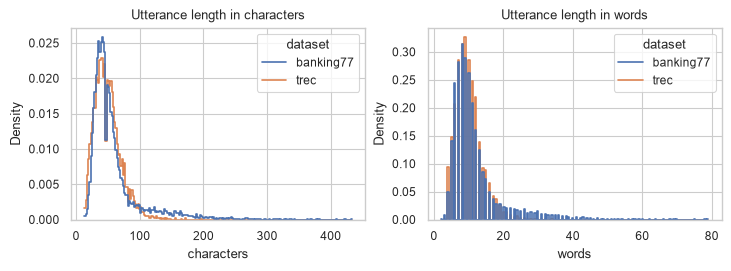

,dataset,split,n,labels,mean_characters,mean_words
0,banking77,test,3080,77,54.232468,10.952597
1,banking77,train,9002,77,59.700289,11.993779
2,banking77,validation,1001,77,57.436563,11.550450
3,trec,test,500,6,35.958000,7.516000
4,trec,train,4897,6,50.720033,10.219726
5,trec,validation,545,6,50.306422,10.148624


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='paper')
eda = data.assign(characters=data['text'].str.len(), words=data['text'].str.split().str.len())
summary = eda.groupby(['dataset', 'split']).agg(n=('example_id', 'size'), labels=('label', 'nunique'), mean_characters=('characters', 'mean'), mean_words=('words', 'mean')).reset_index()
summary.to_csv(PATHS['tables'] / 'dataset_summary.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), constrained_layout=True)
sns.histplot(data=eda, x='characters', hue='dataset', stat='density', common_norm=False, element='step', fill=False, ax=axes[0])
sns.histplot(data=eda, x='words', hue='dataset', stat='density', common_norm=False, element='step', fill=False, ax=axes[1])
axes[0].set_title('Utterance length in characters')
axes[1].set_title('Utterance length in words')
for axis in axes:
    axis.set_ylabel('Density')
fig.savefig(PATHS['figures'] / 'dataset_length_distributions.pdf', bbox_inches='tight')
plt.show()
summary


## Interpretation

BANKING77 is a many-class intent task, whereas TREC has six coarse question classes. Their different label cardinalities and utterance-length distributions should be kept in mind when comparing absolute Macro-F1. All later stages use the exact IDs and splits saved here.